# 05 · Marcos da temporada: previsão de início, pico e fim

Em cada origem $o$ da temporada (SE 1 a 35 de 2024, 2025 e 2026), a trajetória da temporada é o observado na versão da origem (nowcast) até a última semana usada, completado por amostras do modelo até o fim da temporada. Os marcos de cada amostra seguem a definição *a priori* (`vsr_comum.marcos_amostras`: início/fim = fração acumulada 0,10/0,90; pico = argmax da média móvel centrada de 3 semanas), a mesma da verdade em `eda_marcos_temporada.parquet`. Código em `vsr_modelos.py`; método em `docs/METODOLOGIA.md` §12.

- **Modelos:** `naive_sazonal`, `climatologia` (baseline do *timing*), `nb_local`, `arima_fourier` (região e Brasil), `forma_curva` (molde das temporadas anteriores deslocado e esticado, §12.5) `ensemble` (mistura das amostras) e `ensemble_pond` (mistura com pesos ∝ 1/RPS das temporadas anteriores; `vm.ensemble_ponderado`). LightGBM e ETS não geram uma temporada inteira.
- **Nowcast:** as semanas $o - 26 \dots o - 1$ de cada trajetória vêm de uma amostra do nowcast `gamma_rw` (§6.1); o NB parte da mesma amostra.
- **Métricas:** RPS (CRPS discreto, em semanas), erro absoluto da mediana, $P(|\text{erro}| \le 1)$ e cobertura de 80%, por antecedência = semana real − semana da origem.
- **2026:** verdade provisória (temporada em curso); o fim de 2026 não é avaliado.
- **Saídas:** `previsoes_marcos.parquet` (distribuição em 53 semanas) e `avaliacao_marcos.parquet`.

In [1]:
import logging
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

import vsr_modelos as vm
from vsr_comum import P, verificar_ambiente

verificar_ambiente()
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s", stream=sys.stdout, force=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

TIERS = pd.read_csv(P / "tiers_uf.csv").set_index("unidade")["tier"]
VER = (pd.read_parquet(P / "eda_marcos_temporada.parquet").query("serie == @vm.SERIE")
       .melt(id_vars=["nivel", "unidade", "temporada", "completa"], value_vars=list(vm.MARCOS),
             var_name="marco", value_name="semana_real").dropna(subset=["semana_real"]))
VER = VER.loc[VER["completa"] | (VER["marco"] != "fim")].drop(columns="completa")   # fim de 2026 não avaliado
ORIGENS = [o for o in pd.date_range("2023-12-31", "2026-08-09", freq="7D")
           if (o - vm.domingo_se1((o + pd.Timedelta(days=3)).year)).days // 7 + 1 <= 35]
print(f"{len(ORIGENS)} origens: {ORIGENS[0].date()} a {ORIGENS[-1].date()}")

102 origens: 2023-12-31 a 2026-08-09


## 1. Backtest das trajetórias

In [2]:
t0 = time.time()
PREV = vm.backtest_marcos(ORIGENS)
PREV = pd.concat([PREV, vm.ensemble_ponderado(PREV, vm.pontuar_marcos(PREV, VER))], ignore_index=True)
PREV.to_parquet(P / f"previsoes_marcos{vm.sufixo()}.parquet", index=False)
SC = vm.pontuar_marcos(PREV, VER)
SC["grupo"] = np.where(SC["nivel"] == "UF", "UF " + SC["unidade"].map(TIERS), np.where(SC["nivel"] == "BRASIL", "BR", "REGIAO"))
SC["faixa_antec"] = pd.cut(SC["antecedencia"], [-60, 0, 2, 4, 8, 60], labels=["≤ 0", "1–2", "3–4", "5–8", "≥ 9"])
SC.to_parquet(P / f"avaliacao_marcos{vm.sufixo()}.parquet", index=False)
print(f"{len(PREV):,} distribuições em {time.time() - t0:.0f} s; {len(SC):,} avaliadas")

2026-10-20 01:49:40,890 INFO marcos: origem 2023-12-31 (1/102)


2026-10-20 01:50:01,029 INFO marcos: origem 2024-03-10 (11/102)


2026-10-20 01:50:21,405 INFO marcos: origem 2024-05-19 (21/102)


2026-10-20 01:50:42,204 INFO marcos: origem 2024-07-28 (31/102)


2026-10-20 01:51:03,904 INFO marcos: origem 2025-02-02 (41/102)


...

2026-10-20 01:52:10,917 INFO marcos: origem 2026-01-04 (71/102)


2026-10-20 01:52:33,660 INFO marcos: origem 2026-03-15 (81/102)


2026-10-20 01:52:56,081 INFO marcos: origem 2026-05-24 (91/102)


2026-10-20 01:53:18,378 INFO marcos: origem 2026-08-02 (101/102)


62,424 distribuições em 222 s; 55,896 avaliadas


## 2. Acurácia por antecedência

Média sobre origens, unidades e temporadas. Antecedência ≤ 0: o evento já ocorreu (ou ocorre na semana da origem) e é estimado com dados parciais. Os grupos BR e REGIAO e as UFs do tier A são o recorte principal; nos tiers B e C, o início e o pico são avaliados na região (regra *a priori*).

In [3]:
PRINC = SC.loc[SC["grupo"].isin(["BR", "REGIAO", "UF A"])]
for met in ("rps", "ea_mediana", "p_1sem"):
    print(met)
    display(PRINC.pivot_table(index=["marco", "modelo"], columns="faixa_antec", values=met, observed=True)
            .round(2))

rps


faixa_antec            ≤ 0   1–2   3–4   5–8   ≥ 9
marco  modelo                                     
fim    arima_fourier   NaN   NaN   NaN  1.84  0.85
       climatologia    NaN   NaN   NaN  1.17  1.25
       ensemble        NaN   NaN   NaN  0.89  0.87
       ensemble_pond   NaN   NaN   NaN  0.88  0.85
       forma_curva     NaN   NaN   NaN  1.27  1.04
       naive_sazonal   NaN   NaN   NaN  1.26  0.88
       nb_local        NaN   NaN   NaN  0.82  1.02
inicio arima_fourier  0.58  0.99  1.12  1.10  1.56
       climatologia   0.72  1.08  1.15  1.35  2.17
       ensemble       0.59  0.99  1.08  1.19  1.71
       ensemble_pond  0.63  1.05  1.15  1.24  1.77
       forma_curva    0.91  1.88  1.78  1.70  2.20
       naive_sazonal  1.07  1.36  1.43  1.52  1.62
       nb_local       0.62  1.06  1.13  1.19  1.86
pico   arima_fourier  0.47  1.46  1.62  1.82  1.89
       climatologia   1.53  2.68  2.76  2.55  2.91
       ensemble       0.64  1.48  1.64  1.74  2.42
       ensemble_pond  0.64  1.47  1.63  1.75  2.44
       forma_curva    0.45  1.93  2.29  2.04  2.48
       naive_sazonal  1.40  1.56  1.75  2.16  2.90
       nb_local       0.46  1.63  1.78  1.89  2.47

ea_mediana


faixa_antec            ≤ 0   1–2   3–4   5–8   ≥ 9
marco  modelo                                     
fim    arima_fourier   NaN   NaN   NaN  3.00  1.27
       climatologia    NaN   NaN   NaN  1.37  1.67
       ensemble        NaN   NaN   NaN  1.32  1.11
       ensemble_pond   NaN   NaN   NaN  1.26  1.10
       forma_curva     NaN   NaN   NaN  1.95  1.41
       naive_sazonal   NaN   NaN   NaN  1.79  1.22
       nb_local        NaN   NaN   NaN  1.16  1.47
inicio arima_fourier  0.70  1.17  1.33  1.43  2.00
       climatologia   0.92  1.44  1.62  1.86  2.93
       ensemble       0.80  1.35  1.54  1.73  2.28
       ensemble_pond  0.87  1.49  1.60  1.78  2.32
       forma_curva    1.11  2.27  2.18  2.13  2.80
       naive_sazonal  1.20  1.66  1.69  1.79  1.91
       nb_local       0.79  1.29  1.40  1.56  2.34
pico   arima_fourier  0.67  2.14  2.25  2.46  2.63
       climatologia   1.87  3.32  3.33  2.90  3.24
       ensemble       0.72  2.03  2.13  2.34  3.30
       ensemble_pond  0.74  2.02  2.12  2.39  3.31
       forma_curva    0.61  2.65  3.03  2.73  3.29
       naive_sazonal  1.82  2.02  2.40  3.12  3.86
       nb_local       0.62  2.30  2.45  2.60  3.30

p_1sem


faixa_antec            ≤ 0   1–2   3–4   5–8   ≥ 9
marco  modelo                                     
fim    arima_fourier   NaN   NaN   NaN  0.20  0.52
       climatologia    NaN   NaN   NaN  0.35  0.33
       ensemble        NaN   NaN   NaN  0.43  0.49
       ensemble_pond   NaN   NaN   NaN  0.43  0.50
       forma_curva     NaN   NaN   NaN  0.42  0.54
       naive_sazonal   NaN   NaN   NaN  0.48  0.62
       nb_local        NaN   NaN   NaN  0.50  0.50
inicio arima_fourier  0.82  0.51  0.44  0.45  0.33
       climatologia   0.77  0.49  0.42  0.35  0.22
       ensemble       0.75  0.49  0.44  0.40  0.28
       ensemble_pond  0.74  0.47  0.43  0.38  0.27
       forma_curva    0.71  0.35  0.36  0.34  0.20
       naive_sazonal  0.65  0.54  0.47  0.41  0.39
       nb_local       0.84  0.59  0.53  0.48  0.29
pico   arima_fourier  0.80  0.33  0.31  0.32  0.30
       climatologia   0.66  0.15  0.18  0.18  0.16
       ensemble       0.75  0.27  0.26  0.26  0.22
       ensemble_pond  0.75  0.28  0.26  0.26  0.22
       forma_curva    0.82  0.24  0.25  0.31  0.26
       naive_sazonal  0.71  0.39  0.30  0.24  0.21
       nb_local       0.81  0.31  0.30  0.29  0.25

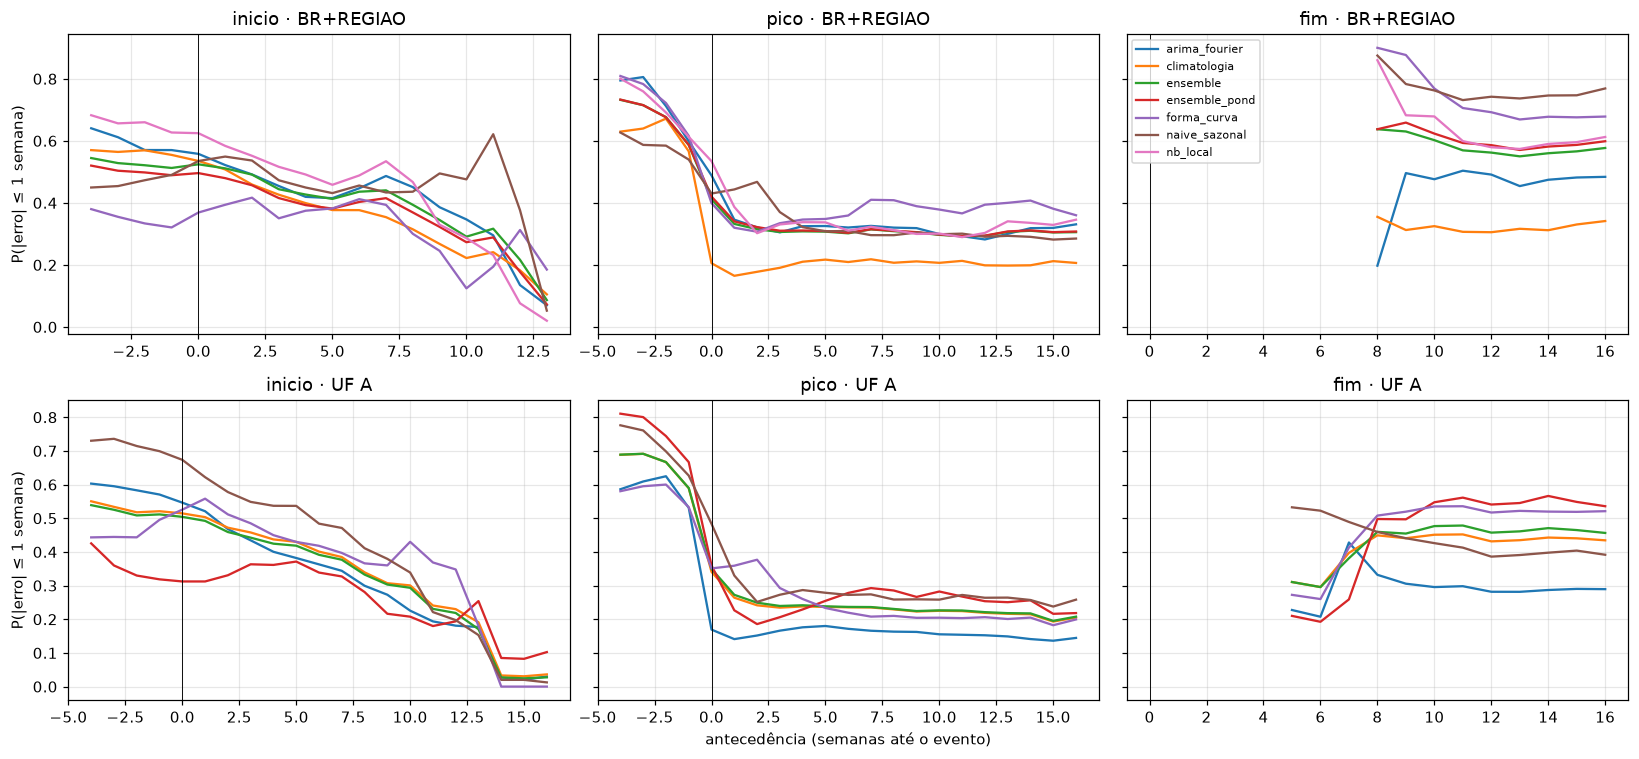

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharey="row")
for j, mc in enumerate(vm.MARCOS):
    for i, grp in enumerate((["BR", "REGIAO"], ["UF A"])):
        ax = axs[i, j]
        d = SC.loc[(SC["marco"] == mc) & SC["grupo"].isin(grp) & SC["antecedencia"].between(-4, 16)]
        for m, g in d.groupby("modelo"):
            ax.plot(*g.groupby("antecedencia")["p_1sem"].mean().pipe(lambda s: (s.index, s.values)), label=m)
        ax.set_title(f"{mc} · {'+'.join(grp)}"); ax.axvline(0, color="k", lw=0.6)
axs[1, 1].set_xlabel("antecedência (semanas até o evento)"); axs[0, 0].set_ylabel("P(|erro| ≤ 1 semana)")
axs[1, 0].set_ylabel("P(|erro| ≤ 1 semana)"); axs[0, -1].legend(fontsize=7); fig.tight_layout()

## 3. Calibração: cobertura do intervalo de 80% (antecedência ≥ 1)

In [5]:
fut = SC.loc[SC["antecedencia"] >= 1]
display(fut.pivot_table(index=["marco", "modelo"], columns="grupo", values="cob80").round(2))

grupo                   BR  REGIAO  UF A  UF B  UF C
marco  modelo                                       
fim    arima_fourier  0.84    0.96   NaN   NaN   NaN
       climatologia   1.00    0.98  0.91  0.88  0.83
       ensemble       1.00    1.00  0.90  0.89  0.89
       ensemble_pond  1.00    1.00  0.89  0.88  0.88
       forma_curva    1.00    0.70  0.73  0.66  0.51
       naive_sazonal  1.00    0.85  0.76  0.68  0.79
       nb_local       0.97    0.95  0.79  0.78  0.77
inicio arima_fourier  0.45    0.58   NaN   NaN   NaN
       climatologia   0.55    0.62  0.68  0.82  0.67
       ensemble       0.62    0.69  0.70  0.72  0.87
       ensemble_pond  0.45    0.59  0.68  0.73  0.86
       forma_curva    0.38    0.47  0.43  0.66  0.59
       naive_sazonal  0.10    0.29  0.38  0.41  0.78
       nb_local       0.45    0.53  0.58  0.58  0.52
pico   arima_fourier  0.89    0.74   NaN   NaN   NaN
       climatologia   1.00    0.98  0.92  0.85  0.93
       ensemble       1.00    0.91  0.82  0.87  0.96
       ensemble_pond  1.00    0.90  0.80  0.87  0.96
       forma_curva    0.95    0.79  0.57  0.71  0.77
       naive_sazonal  0.98    0.66  0.58  0.63  0.91
       nb_local       0.85    0.68  0.68  0.84  0.91

## 4. Teste de sinal pareado contra os baselines

Por par unidade-temporada, RPS médio nas origens com antecedência de 1 a 8 semanas (decisão acionável). Vitória = RPS do modelo < RPS do baseline; teste binomial bilateral com p = 0,5 (empates descartados). Recorte principal: BR, regiões e UFs do tier A. Dois baselines: `climatologia` (amostra cada semana de forma independente e, fora da temporada, gera picos espúrios tardios, sendo fraca para *timing*) e `naive_sazonal` (formato da temporada anterior).

In [6]:
acao = PRINC.loc[PRINC["antecedencia"].between(1, 8)]
par = acao.pivot_table(index=["marco", "unidade", "temporada"], columns="modelo", values="rps")
linhas = []
for base in ("climatologia", "naive_sazonal"):
    for mc, d in par.groupby(level="marco"):
        for m in [c for c in d.columns if c not in ("climatologia", "naive_sazonal")]:
            x = d[[m, base]].dropna()
            dif = x[m] - x[base]
            v, n = int((dif < 0).sum()), int((dif != 0).sum())
            linhas.append({"baseline": base, "marco": mc, "modelo": m, "vitorias": v, "pares": n,
                           "p_valor": binomtest(v, n, 0.5).pvalue if n else np.nan,
                           "rps_modelo": x[m].mean(), "rps_base": x[base].mean()})
SINAL = pd.DataFrame(linhas)
display(SINAL.round(3))

,baseline,marco,modelo,vitorias,pares,p_valor,rps_modelo,rps_base
0,climatologia,fim,arima_fourier,0,1,1.000,1.839,0.826
1,climatologia,fim,ensemble,8,12,0.388,0.811,1.251
2,climatologia,fim,ensemble_pond,8,12,0.388,0.793,1.251
3,climatologia,fim,forma_curva,7,12,0.774,1.016,1.251
4,climatologia,fim,nb_local,8,12,0.388,0.877,1.251
5,climatologia,inicio,arima_fourier,14,18,0.031,1.066,1.228
6,climatologia,inicio,ensemble,35,63,0.450,1.114,1.227
7,climatologia,inicio,ensemble_pond,35,63,0.450,1.173,1.227
8,climatologia,inicio,forma_curva,21,63,0.011,1.768,1.227
9,climatologia,inicio,nb_local,35,63,0.450,1.135,1.227


## 5. Exemplo: distribuição prevista do pico ao longo da temporada

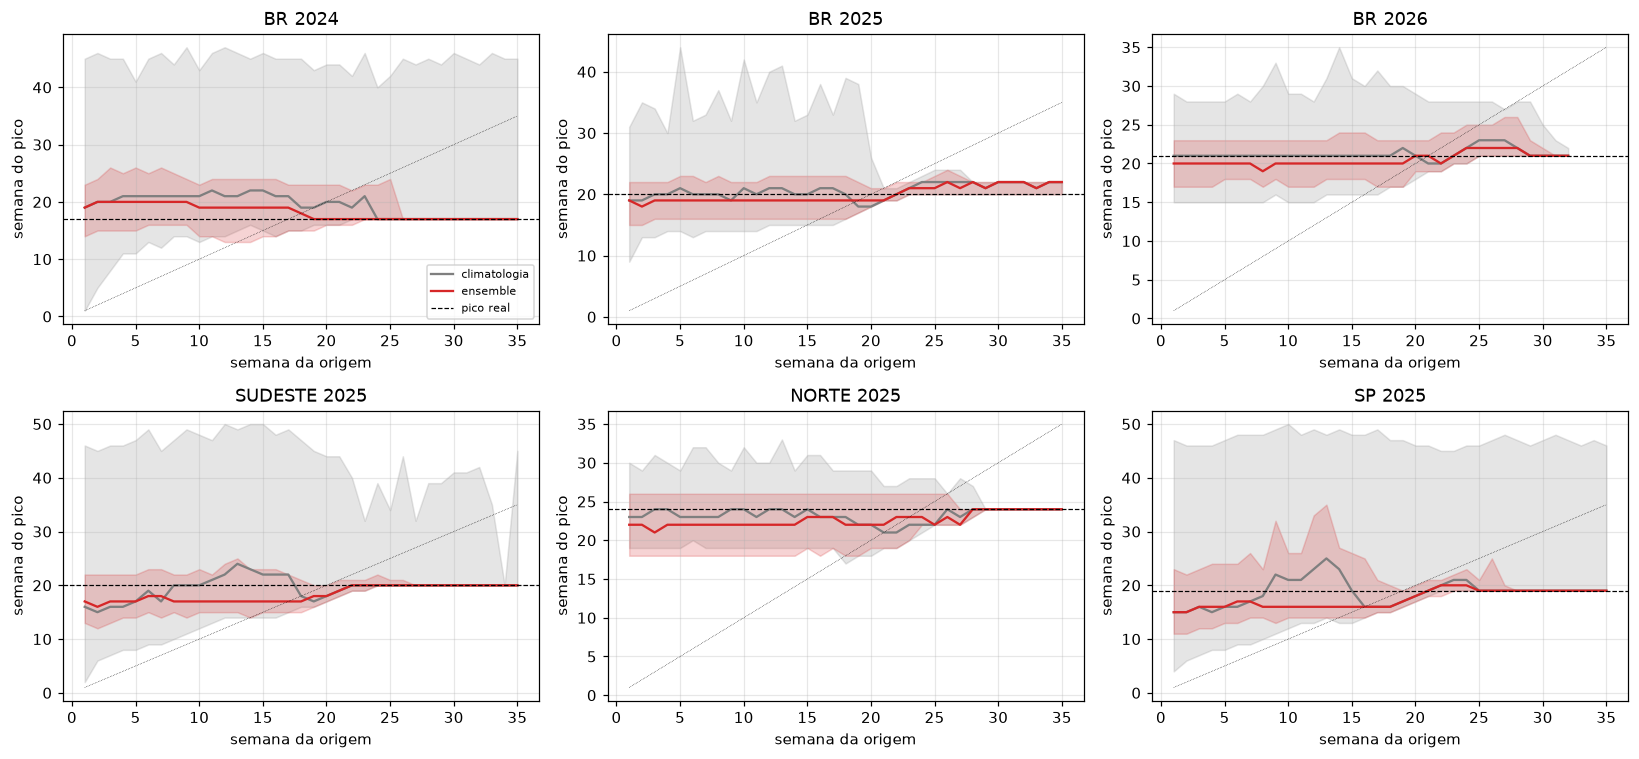

In [7]:
EX = [("BR", 2024), ("BR", 2025), ("BR", 2026), ("SUDESTE", 2025), ("NORTE", 2025), ("SP", 2025)]
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for ax, (u, t) in zip(axs.flat, EX):
    for m, cor in (("climatologia", "tab:gray"), ("ensemble", "tab:red")):
        d = SC.loc[(SC["unidade"] == u) & (SC["temporada"] == t) & (SC["marco"] == "pico") & (SC["modelo"] == m)]
        p = PREV.loc[(PREV["unidade"] == u) & (PREV["temporada"] == t) & (PREV["marco"] == "pico")
                     & (PREV["modelo"] == m)].sort_values("semana_origem")
        F = np.cumsum(p[vm.COLS_P].to_numpy(), 1)
        q = lambda a: (F >= a).argmax(1) + 1  # noqa: E731
        ax.fill_between(p["semana_origem"], q(0.1), q(0.9), color=cor, alpha=0.2)
        ax.plot(p["semana_origem"], q(0.5), color=cor, label=m)
    real = VER.query("unidade == @u and temporada == @t and marco == 'pico'")["semana_real"]
    if len(real):
        ax.axhline(real.iloc[0], color="k", ls="--", lw=0.8, label="pico real")
    ax.plot([1, 35], [1, 35], color="k", lw=0.4, ls=":")
    ax.set_title(f"{u} {t}"); ax.set_xlabel("semana da origem"); ax.set_ylabel("semana do pico")
axs[0, 0].legend(fontsize=7); fig.tight_layout()

## 5b. Sensibilidade à definição de início e fim

As distribuições previstas (definição *a priori*) pontuadas contra as verdades alternativas de `02_eda` §7b (MEM e limiar de taxa). Não há nova previsão: mede se as conclusões sobre os modelos dependem da definição usada na verdade. Teste de sinal contra o `naive_sazonal`, antecedência 1–8 semanas, BR + regiões + UF A.

In [8]:
E = pd.read_parquet(P / "eda_marcos_temporada.parquet").query("serie == @vm.SERIE")
linhas = []
for alt in (("mem", "taxa") if vm.SERIE == "vsr" else ()):   # definições alternativas só para o vsr
    va = (E.rename(columns={"inicio_" + alt: "inicio_alt", "fim_" + alt: "fim_alt"})
          .melt(id_vars=["nivel", "unidade", "temporada", "completa"], value_vars=["inicio_alt", "fim_alt"],
                var_name="marco", value_name="semana_real").dropna(subset=["semana_real"]))
    va["marco"] = va["marco"].str.replace("_alt", "")
    va = va.loc[va["completa"] | (va["marco"] != "fim")].drop(columns="completa")
    sa = vm.pontuar_marcos(PREV.loc[PREV["marco"].isin(["inicio", "fim"])], va)
    sa = sa.loc[sa["unidade"].isin(PRINC["unidade"].unique()) & sa["antecedencia"].between(1, 8)]
    par = sa.pivot_table(index=["marco", "unidade", "temporada"], columns="modelo", values="rps")
    for mc, d in par.groupby(level="marco"):
        for m in [c for c in d.columns if c != "naive_sazonal"]:
            x = d[[m, "naive_sazonal"]].dropna()
            dif = x[m] - x["naive_sazonal"]
            v, n = int((dif < 0).sum()), int((dif != 0).sum())
            linhas.append({"definicao": alt, "marco": mc, "modelo": m, "vitorias": v, "pares": n,
                           "p_valor": binomtest(v, n, 0.5).pvalue if n else np.nan,
                           "ea_modelo": sa.loc[(sa["marco"] == mc) & (sa["modelo"] == m), "ea_mediana"].mean()})
SENS = pd.DataFrame(linhas)
display(SENS.round(3))

""


## 6. Resumo

In [9]:
r = PRINC.loc[PRINC["antecedencia"].between(1, 8)].groupby(["marco", "modelo"])[["rps", "ea_mediana", "p_1sem"]].mean()
print("antecedência 1–8 semanas, BR + regiões + UF A:")
print(r.round(2).to_string())
print("\nteste de sinal (p < 0,05):")
print(SINAL.loc[SINAL["p_valor"] < 0.05, ["baseline", "marco", "modelo", "vitorias", "pares", "p_valor"]]
      .round(4).to_string(index=False))

antecedência 1–8 semanas, BR + regiões + UF A:
                       rps  ea_mediana  p_1sem
marco  modelo                                 
fim    arima_fourier  1.84        3.00    0.20
       climatologia   1.17        1.37    0.35
       ensemble       0.89        1.32    0.43
       ensemble_pond  0.88        1.26    0.43
       forma_curva    1.27        1.95    0.42
       naive_sazonal  1.26        1.79    0.48
       nb_local       0.82        1.16    0.50
inicio arima_fourier  1.08        1.34    0.46
       climatologia   1.23        1.69    0.40
       ensemble       1.11        1.58    0.43
       ensemble_pond  1.17        1.66    0.42
       forma_curva    1.77        2.18    0.35
       naive_sazonal  1.45        1.73    0.46
       nb_local       1.14        1.45    0.52
pico   arima_fourier  1.68        2.33    0.32
       climatologia   2.64        3.11    0.17
       ensemble       1.65        2.21    0.26
       ensemble_pond  1.65        2.23    0.26
       forma_